# Homework 2. Proof-of-Work blockchain

The tasks use the `blockchain` package from https://github.com/0xBoringWozniak/BlockchainExample.
Run this notebook from the root of the cloned repository (or add the repository to `sys.path`).

```bash
git clone https://github.com/0xBoringWozniak/BlockchainExample
cd BlockchainExample
python -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt matplotlib jupyter
jupyter notebook
```

In [32]:
import time
import matplotlib.pyplot as plt
import threading
from typing import Optional

from blockchain import Transaction, Block, BlockchainPeer, BlockchainMainnet

### Task 1. Form the following block and calculate its hash.

Build `Transaction` and `Block` objects from the dictionary below and print `block.compute_hash()`.
All timestamps equal `SEMINAR_TS`, so everybody should get the same hash.

In [38]:
block_data = {
    'index': 4,
    'timestamp': 1790360100,
    'previous_hash': '0009e52e043a9f83524d01485dda65fe16b6d0dd4239c1c938834be249a432e3',
    'nonce': 0,
    'author': 'Satoshi',
    'transactions': [
        {
            'sender_address': 'Alice',
            'recipient_address': 'Bob',
            'value': 10,
            'data': 'Hello Bob!',
            'timestamp': 1790360100,
        },
        {
            'sender_address': 'Bob',
            'recipient_address': 'Alice',
            'value': 5,
            'data': 'Hello Alice!',
            'timestamp': 1790360100,
        }
    ]
}



In [39]:
transactions_list = [
    Transaction(
        sender_address=tx['sender_address'],
        recipient_address=tx['recipient_address'],
        value=tx['value'],
        data=tx['data'],
        timestamp=tx['timestamp']
    )
    for tx in block_data['transactions']
]

block = Block(
    index=block_data['index'],
    author=block_data['author'],
    transactions=transactions_list,
    timestamp=block_data['timestamp'],
    previous_hash=block_data['previous_hash'],
    nonce=block_data['nonce']  
)


block_hash = block.compute_hash()
print(block_hash)

c1daa39f8dfe83dfd2e4c7707031ffd4048cdd2b9d2a904c63b113a7f9e206a0


### Task 2. Run PoW algorithm and find the proof of this block (from task 1) with difficulty=3.

`proof_of_work` is a method of a peer, so set `BlockchainPeer.difficulty = 3`, create a peer and call `peer.proof_of_work(block)`.
Print the nonce, the resulting hash and the number of attempts (`peer.mining_attempts`). How many attempts did you expect on average?

In [29]:
BlockchainPeer.difficulty = 3
peer = BlockchainPeer(peer_name="Miner1", hashrate=50000)
found_hash = peer.proof_of_work(block)


print(f"nonce: {block.nonce}")
print(f"resulting hash: {found_hash}")
print(f"number of attempts: {peer.mining_attempts}")

nonce: 2121
resulting hash: 0008e9836de185bc414beb3870f831505207cf98d6e3dccd345bd317945eafe8
number of attempts: 2122


difficulty = 3, т.е. целевой хэш должен начинаться 000...
В 16-чной системе 16 символов: 0-9 и a-f.
Вероятность, что три символа подряд окажутся '0': 1/16*1/16*1/16=1/4096.
E[кол-во попыток до найденного Nonce]=1/p=4096

### Task 3. Init a single peer and mine 2 blocks with the same 2 transactions from task 1. Why are the hashes of these blocks not the same?

* Create the two transactions, add them to the peer, mine a block and append it with `peer.receive_block(peer.mine())`
* For the second block create the two transactions **again** as new objects and repeat
* Print both blocks and explain where they differ
* Now try to add the original `Transaction` objects from the first block once more. What does `peer.validate_transaction(tx)` say and why does the network need this check?

In [31]:
peer = BlockchainPeer(peer_name="Miner2")

tx1_1 = Transaction(
    sender_address='Alice', recipient_address='Bob',
    value=10, data='Hello Bob!')
tx2_1 = Transaction(
    sender_address='Bob', recipient_address='Alice',
    value=5, data='Hello Alice!')

peer.add_new_transaction(tx1_1)
peer.add_new_transaction(tx2_1)

mined_block_1 = peer.mine()
peer.receive_block(mined_block_1)

print(f"nonce: {mined_block_1.nonce}")
print(f"hash блока 1: {mined_block_1.hash}")
print(f"amount of tx: {len(mined_block_1.transactions)}")
for tx in mined_block_1.transactions:
    print(f"{tx.sender_address} -> {tx.recipient_address}: {tx.value} | tx_hash: {tx.tx_hash}")


tx1_2 = Transaction(
    sender_address='Alice', recipient_address='Bob',
    value=10, data='Hello Bob!')
tx2_2 = Transaction(
    sender_address='Bob', recipient_address='Alice',
    value=5, data='Hello Alice!')

peer.add_new_transaction(tx1_2)
peer.add_new_transaction(tx2_2)

mined_block_2 = peer.mine()
peer.receive_block(mined_block_2)

print(f"\nnonce: {mined_block_2.nonce}")
print(f"hash блока 2: {mined_block_2.hash}")
print(f"amount of tx: {len(mined_block_2.transactions)}")
for tx in mined_block_2.transactions:
    print(f"{tx.sender_address} -> {tx.recipient_address}: {tx.value} | tx_hash: {tx.tx_hash}")


print(f"hash блока 1: {mined_block_1.hash}")
print(f"hash блока 2: {mined_block_2.hash}")
print(f"\ntimestamp блока 1: {mined_block_1.timestamp}")
print(f"timestamp блока 2: {mined_block_2.timestamp}")

original_tx = mined_block_1.transactions[0]
print(f"Можем добавить: {original_tx.sender_address} -> {original_tx.recipient_address}, value={original_tx.value} ?")
validation_result = peer.validate_transaction(original_tx)
print(f"result validate_transaction: {validation_result}")

nonce: 2007
hash блока 1: 000d4ebf959f9407d776db57b2e9e614e656f0c371b98b107057aa43af6fd955
amount of tx: 2
Alice -> Bob: 10 | tx_hash: 1ac0e7db54d95282b5be9db5edb625ebf2573aa17230eb6053298fa88072a03d
Bob -> Alice: 5 | tx_hash: 66a4d7e44a244cd352c362dbfd49b100dd6a79773417f52e6f7f317a44850f8e

nonce: 574
hash блока 2: 00054b042f4c922b583a1e592da78e2c9030fa7f4d6e6249a556bbceed7eace0
amount of tx: 2
Alice -> Bob: 10 | tx_hash: 4baee8517da7cac398bd2f3d8710ea7bc8ff1c7ee12408308c5c6c1850cde7f0
Bob -> Alice: 5 | tx_hash: 37727da5610f52e26dacffd2116a362c6dcf06352e872881e54c3d274297d0ad
hash блока 1: 000d4ebf959f9407d776db57b2e9e614e656f0c371b98b107057aa43af6fd955
hash блока 2: 00054b042f4c922b583a1e592da78e2c9030fa7f4d6e6249a556bbceed7eace0

timestamp блока 1: 1790852147.2011595
timestamp блока 2: 1790852147.2762535
Можем добавить: Alice -> Bob, value=10 ?
result validate_transaction: already in chain (replay)


### Task 4. Mine 100 blocks with 5 peers (max 5 transactions per block). Plot the distribution of mined blocks by peer.

Setup:

* `BlockchainPeer.difficulty = 3`, otherwise 100 blocks take minutes.
* Give the peers different computing power through the `hashrate` argument, for example `40_000, 20_000, 10_000, 10_000, 5_000` hashes per second.
* The package has no block size limit. Implement it yourself in a subclass: a block may include at most 5 transactions, the rest stay in the mempool.
* Before every round gossip a few new transactions with `mainnet.add_new_transaction(...)`, then call `mainnet.run_mining()`. The winner is `result.winner`.
* Plot a bar chart: blocks mined by each peer next to the peer's share of the total hashrate.

Questions:

1. Which peer will have the most mined blocks when N ≫ 100? Does the distribution of blocks converge to something? To what exactly?
2. Blocks are mined asynchronously and the winner of a single round is random. Why does the share still converge?
3. In the old version of this repository the winner was the peer that finished mining **last** (the announcement file was overwritten by every peer and the network read it after a one second sleep). What would the distribution look like in that version and why would it be wrong for a PoW network?

Ответы на вопросы:
1. При 𝑁≫100 больше всего блоков добудет Peer-1 с наибольшим хэшрейтом 40 000 H/s, т.к. у него наибольшая вычислительная мощность.
Распределение добытых блоков сходится к доле хэшрейта каждого узла в общей мощности сети.
2. По закону больших чисел: увеличение количества независимых испытаний среднее значение по выборке сходится по вероятности к мат.ожиданию.
3. В старой версии распределение было бы обратным: чаще всего бы добывал блоки узел с хэшрейтом 5 000 H/s. Идея PoW в том, что нужно настолько усложнить участнику добычу блока, что злоупотребления станут принципиально нерентабельными - здесь выходит наоборот, добывает блок тот, чьи затраты меньше. Вероятны злоупотребления услугами

In [33]:
BlockchainPeer.difficulty = 3
class LimitedBlockchainPeer(BlockchainPeer):
    MAX_TRANSACTIONS = 5

    def mine(self, stop: Optional[threading.Event] = None) -> Optional[Block]:
        """
        Same as BlockchainPeer.mine, but the candidate block includes
        at most MAX_TRANSACTIONS transactions from the mempool.
        """
        if not self.unconfirmed_transactions:
            self.mining_status = BlockchainPeer.IDLE
            return None
        
        last_block: Block = self.last_block
        
        txs_to_mine = self.unconfirmed_transactions[:self.MAX_TRANSACTIONS]
        
        new_block = Block(
            index=last_block.index + 1,
            transactions=txs_to_mine,
            author=self.peer_name,
            timestamp=time.time(),
            previous_hash=last_block.hash,
            nonce=0,
        )
        
        proof = self.proof_of_work(new_block, stop)
        
        if proof is None:
            return None
        
        new_block.hash = proof
        return new_block


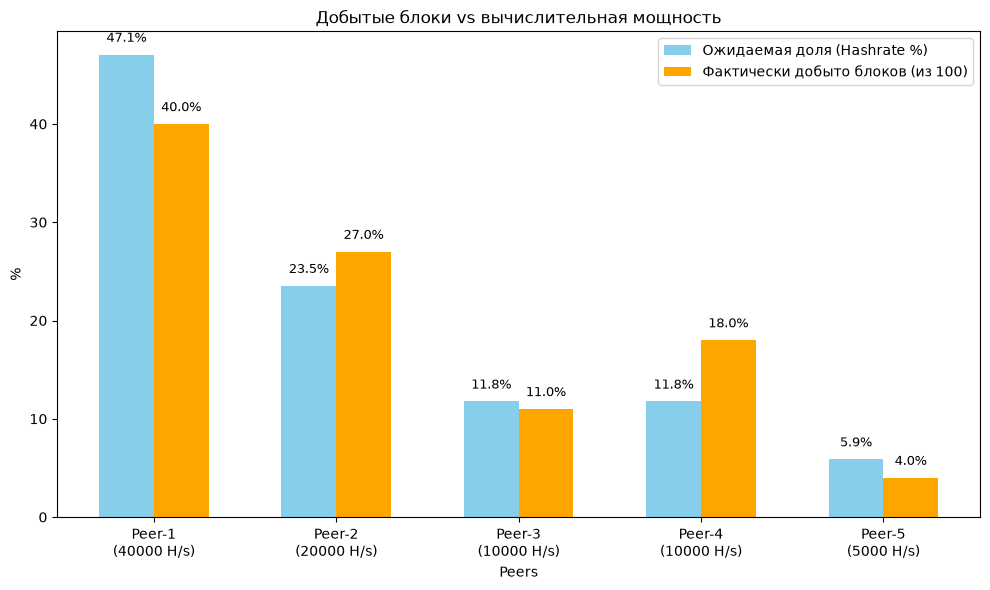

In [37]:
HASHRATES = [40_000, 20_000, 10_000, 10_000, 5_000]
names = [f'Peer-{i+1}' for i in range(5)]
peers = [LimitedBlockchainPeer(name, hr) for name, hr in zip(names, HASHRATES)]
mainnet = BlockchainMainnet(peers)

wins = {name: 0 for name in names}
rounds = 100
accounts = ['Alice', 'Bob', 'Charlie', 'Dave', 'Max']


for i in range(rounds):
    import random
    num_tx = random.randint(3, 8)
    for _ in range(num_tx):
        sender, recipient = random.sample(accounts, 2)
        tx = Transaction(sender, recipient, value=random.randint(1, 50))
        mainnet.add_new_transaction(tx)
    
    result = mainnet.run_mining()
    
    if result and result.winner:
        wins[result.winner.peer_name] += 1


total_hashrate = sum(HASHRATES)
expected_shares = [hr / total_hashrate * 100 for hr in HASHRATES]
actual_shares = [wins[name] / rounds * 100 for name in names]

x = range(len(names))
width = 0.30

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar([i - width/2 for i in x], expected_shares, width, label='Ожидаемая доля (Hashrate %)', color='skyblue')
bars2 = ax.bar([i + width/2 for i in x], actual_shares, width, label=f'Фактически добыто блоков (из {rounds})', color='orange')

ax.set_xlabel('Peers')
ax.set_ylabel('%')
ax.set_title('Добытые блоки vs вычислительная мощность')
ax.set_xticks(x)
ax.set_xticklabels([f"{n}\n({hr} H/s)" for n, hr in zip(names, HASHRATES)])
ax.legend()

for bar in bars1 + bars2:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 1, f'{yval:.1f}%', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

A peer owns a share $p$ of the total hashrate of the network. Every block is a fresh lottery: the peer that finds a valid nonce first wins, and with equal hardware the number of attempts each peer needs is geometrically distributed.

1. What is the expected share of blocks mined by this peer over a long run? Justify in one or two sentences.
2. What is the probability that this peer mines $k$ blocks in a row? Compute it for $p = 0.3$ and $k = 6$.
3. Suppose a peer with $p > 0.5$ starts building its own private chain from some block in the past while the rest of the network keeps extending the public chain. What happens to the longest chain rule after enough time? Why is $p = 0.5$ the threshold?

1. Ожидаемая доля в точности равна p. Каждый раз майнинга блока — это независимое испытание Бернулли, в котором узел побеждает с вероятностью p (пропорциональной его доле хэшрейта) и согласно ЗБЧ эмпирическая доля добытых этим узлом блоков сходится к теоретической вероятности p.
2. Поскольку добыча каждого блока — это независимое событие с вероятностью успеха p, вероятность добыть k блоков: P=p^k=0.3^6=0.000729
3. Приватная цепь атакующего растет со скоростью p блоков в единицу времени, в то время как публичная цепь (остальная сеть) растет со скоростью (1 − p). Поскольку p > 0.5, приватная цепь растет быстрее публичной. По прошествии некоторого времени приватная цепь станет длиннее публичной и правилу самой длинной цепи, вся сеть признает цепь атакующего истинной и переключится на неё.

### Task 5. Difficulty versus time.

Measure the average mining time of a block for `difficulty` 2..6 and plot it.

* Plot the mean time and the mean number of attempts against difficulty
* Explain the growth. What is the factor between neighbouring difficulties?

Сложность 2: среднее время = 0.0128 сек, среднее число попыток = 465
Сложность 3: среднее время = 0.0115 сек, среднее число попыток = 465
Сложность 4: среднее время = 0.2628 сек, среднее число попыток = 9166
Сложность 5: среднее время = 7.6197 сек, среднее число попыток = 327009


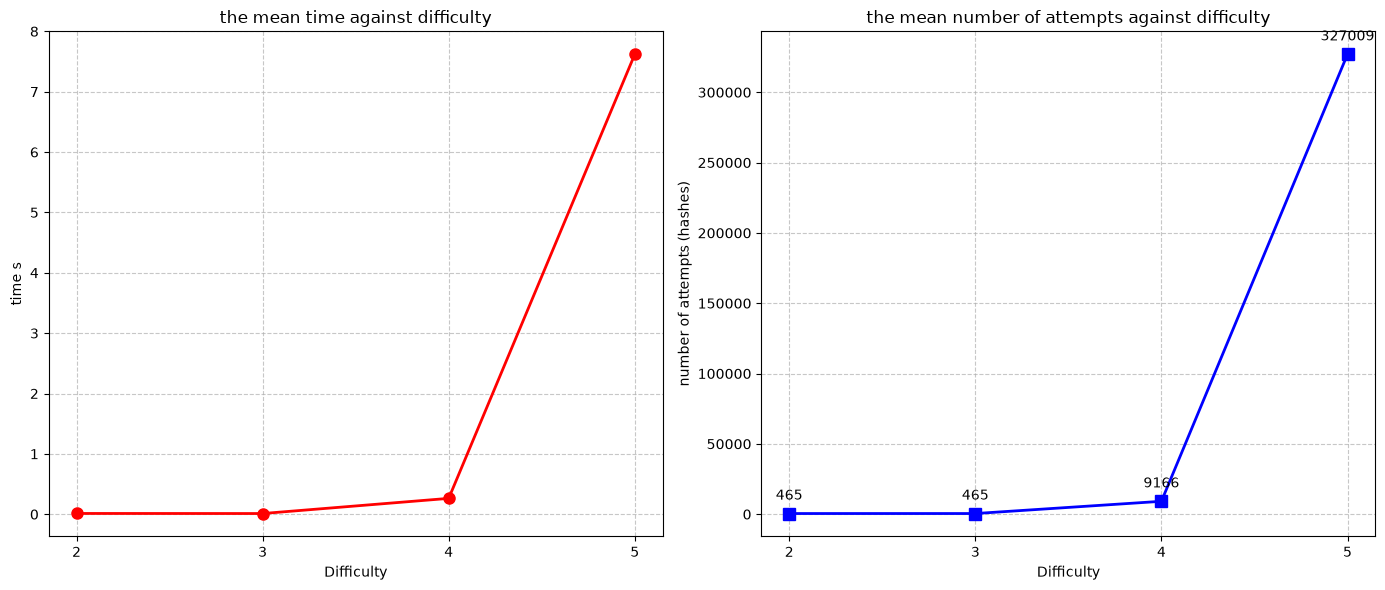

In [ ]:
difficulties = [2, 3, 4, 5]
trials = 10
results = []

dtx = Transaction('Alice', 'Bob', 10, data='test')
dblock = Block(index=1, transactions=[dtx], author='Tester', 
                    timestamp=time.time(), previous_hash='0', nonce=0)

for d in difficulties:
    BlockchainPeer.difficulty = d
    attempts_list = []
    time_list = []
    
    for _ in range(trials):
        peer = BlockchainPeer(peer_name="BenchmarkPeer", hashrate=None)
        
        start_time = time.perf_counter()
        peer.proof_of_work(dblock)
        end_time = time.perf_counter()
        
        attempts_list.append(peer.mining_attempts)
        time_list.append(end_time - start_time)
        
    mean_attempts = sum(attempts_list) / len(attempts_list)
    mean_time = sum(time_list) / len(attempts_list)
    
    results.append({
        'difficulty': d,
        'mean_attempts': mean_attempts,
        'mean_time': mean_time
    })
    print(f"Сложность {d}: среднее время = {mean_time:.4f} сек, среднее число попыток = {mean_attempts:.0f}")


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

d = [r['difficulty'] for r in results]
times = [r['mean_time'] for r in results]
attempts = [r['mean_attempts'] for r in results]

ax1.plot(d, times, marker='o', color='red', linewidth=2, markersize=8)
ax1.set_title('the mean time against difficulty')
ax1.set_xlabel('Difficulty')
ax1.set_ylabel('time s')
ax1.set_xticks(d)
ax1.grid(True, linestyle='--', alpha=0.7)

ax2.plot(d, attempts, marker='s', color='blue', linewidth=2, markersize=8)
ax2.set_title('the mean number of attempts against difficulty')
ax2.set_xlabel('Difficulty')
ax2.set_ylabel('number of attempts (hashes)')
ax2.set_xticks(d)
ax2.grid(True, linestyle='--', alpha=0.7)


for i, txt in enumerate(attempts):
    ax2.annotate(f'{int(txt)}', (d[i], attempts[i]), textcoords="offset points", xytext=(0,10), ha='center')

plt.tight_layout()
plt.show()


1. Рост экспоненциальный. На графиках c логарифмической шкалой по оси Y (ax.set_yscale('log')), обе кривые превратятся в почти прямые линии.
2. Множитель между соседними уровнями сложности = 16.

Let the difficulty be $d$ leading hex zeros and let the miner try $H$ hashes per second.

1. What is the expected number of attempts to find a block, and the expected time? Express the same difficulty in leading zero **bits**.
2. What is the probability of finding a block within the expected number of attempts? Compute the limit for large $d$.
3. Let some server does about $2 \cdot 10^5$ hashes per second. Which difficulty in hex zeros gives a block roughly every 10 minutes?

1. Каждая попытка — независимое испытание Бернулли с вероятностью успеха: p=1/16^d. Тогда E[attempts]=16^d. Если майнер делает H хэшей в секунду, то ожидаемое время E[time]=16^d/H секунд. d hex zeros=4d leading zero bits.
2. Ожидаемое число попыток N = 16^d. Вероятность не найти блок за N попыток = (1-p)^N. Вероятность найти блок за N попыток = 1-(1-p)^N=1-(1-1/N)^N. Для больших d (1-1/N)^N стремится к 1/e. Тогда Вероятность найти блок за N попыток при d стремится к бесконечности = 1-1/e=0.63
3. E[attempts]=H*t=1.2*10^8=16^d. d=lg(1.2*10^8)/lg(16)=6.7, примерно 7.


​
